In [1]:
import pathlib
import sys, os
import matplotlib.pyplot as plt
import numpy as np
import scienceplots

# gives the absolute path of .py and .ipynb where you are running your code. 
currentDir = pathlib.Path(os.path.abspath(""))
dataPath = str((currentDir / "motion_data").resolve())
plot_dir = currentDir / "motion_plots"

# 窗口平均函数
def moving_average(data, window_size):
    """对数据进行移动平均滤波"""
    window = np.ones(int(window_size)) / float(window_size)
    return np.convolve(data, window, 'same')

# 通过速度差分计算加速度的函数
def calculate_acceleration_from_velocity(time, velocity):
    """
    通过速度差分计算加速度
    加速度[i] = (速度[i] - 速度[i-1]) / (时间[i] - 时间[i-1])
    第一个点的加速度设为0
    """
    acceleration = np.zeros_like(velocity)
    for i in range(1, len(velocity)):
        dt = time[i] - time[i-1]
        if dt > 0:  # 避免除以零
            acceleration[i] = (velocity[i] - velocity[i-1]) / dt
    return acceleration

with plt.style.context(['science','ieee']):
  start_from = 5
  for i in range(4):
    motionData = np.genfromtxt(dataPath + f"/motion_{i}.csv", delimiter=",").transpose()
    # 假设数据列的顺序为：时间、位置、速度、加速度、力
    # 如果顺序不同，请根据实际数据调整索引
    time = motionData[0][start_from:]        # 时间
    position = motionData[1][start_from:]   # 位置
    velocity = motionData[2][start_from:]    # 速度
    # 计算时间步长
    dt = time[1] - time[0] if len(time) > 1 else 0.001
    
    acceleration_smoothed = calculate_acceleration_from_velocity(time, velocity)[start_from:]
    acceleration = motionData[3][start_from:] # 加速度
    force = motionData[4][start_from:]       # 力

    # 创建2x2的子图布局
    fig, axes = plt.subplots(3, 1, figsize=(15, 10))
    fig.suptitle(f'Motion {i} data', fontsize=16, fontweight='bold')

    # 位置-时间图
    axes[0].plot(time, position, 'b-', linewidth=2)
    axes[0].set_title('Position vs Time')
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Position')
    axes[0].grid(True, alpha=0.3)

    # 速度-时间图
    axes[1].plot(time, velocity, 'r-', linewidth=2)
    axes[1].set_title('Velocity vs Time')
    axes[1].set_xlabel('Time (s)')
    axes[1].set_ylabel('Velocity')
    axes[1].grid(True, alpha=0.3)
    
    # # 加速度-时间图
    # # axes[1, 0].plot(time, acceleration_smoothed, 'g-', linewidth=2)
    # axes[1, 0].plot(time, acceleration, 'r-', linewidth=1)
    # # axes[1, 0].plot(time, acceleration, 'g-', linewidth=2)
    # axes[1, 0].set_title('Accel vs Time')
    # axes[1, 0].set_xlabel('Time (s)')
    # axes[1, 0].set_ylabel('Accel')
    # axes[1, 0].grid(True, alpha=0.3)

    # 力-时间图
    axes[2].plot(time, force, 'purple', linewidth=2)
    axes[2].set_title('Force vs Time')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('Force')
    axes[2].grid(True, alpha=0.3)

    # 调整布局
    plt.tight_layout()
    plt.savefig(plot_dir / f'motion_plot_{i}.png', dpi=300, bbox_inches='tight')
    plt.show()

  

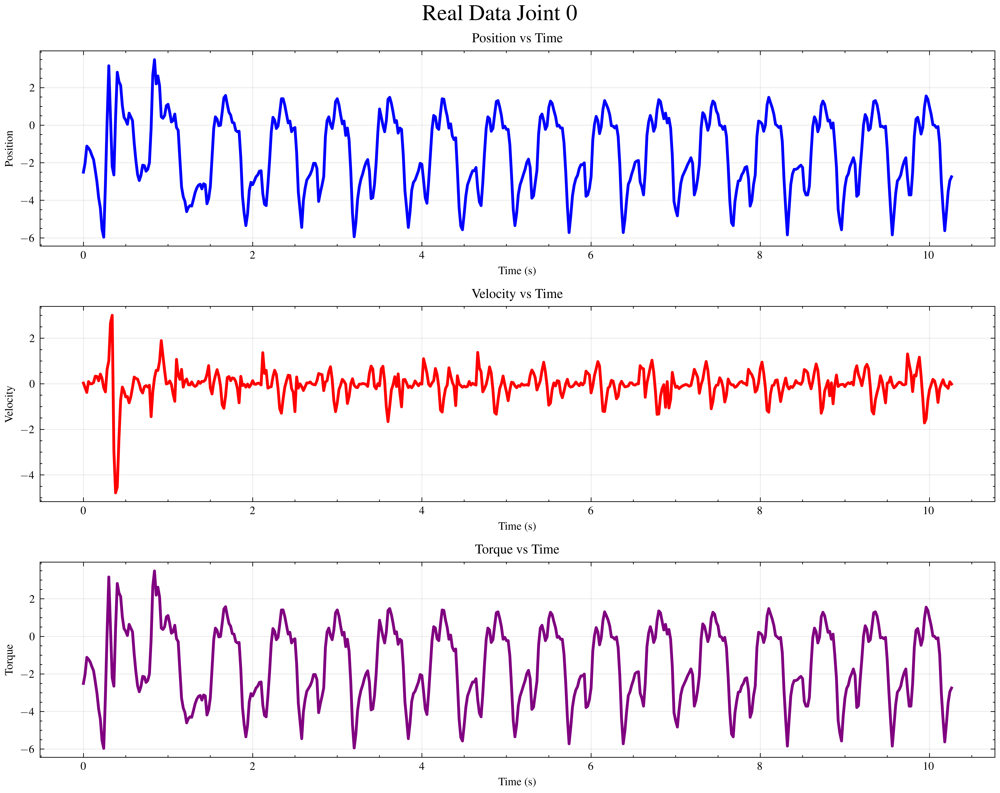

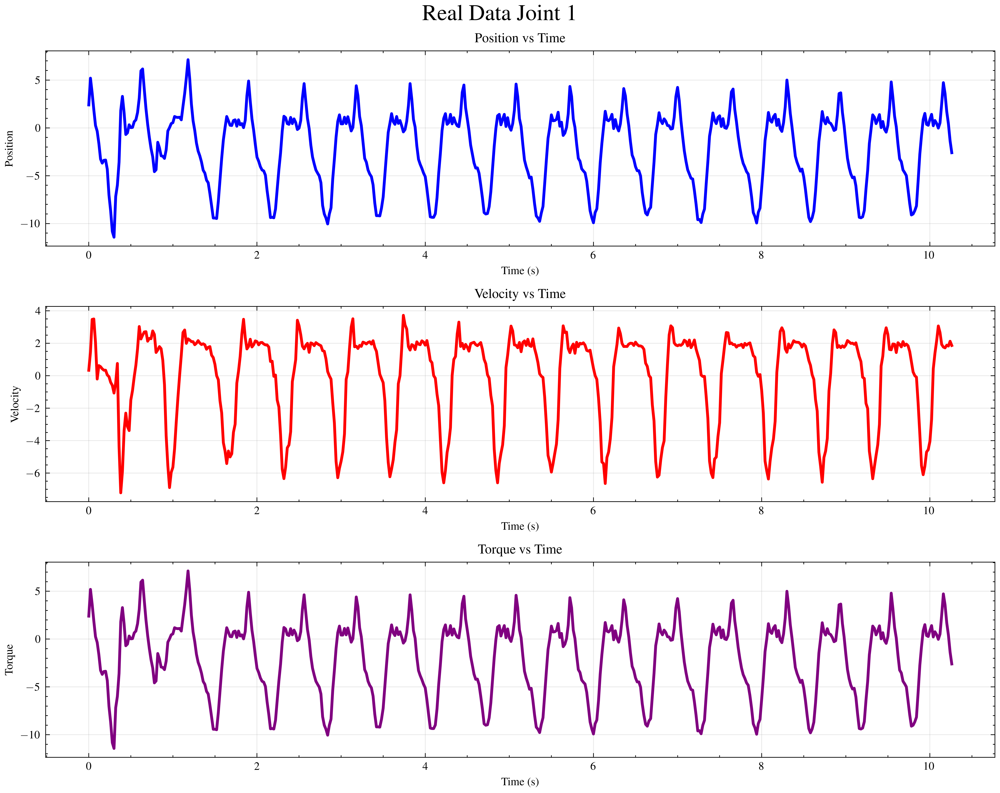

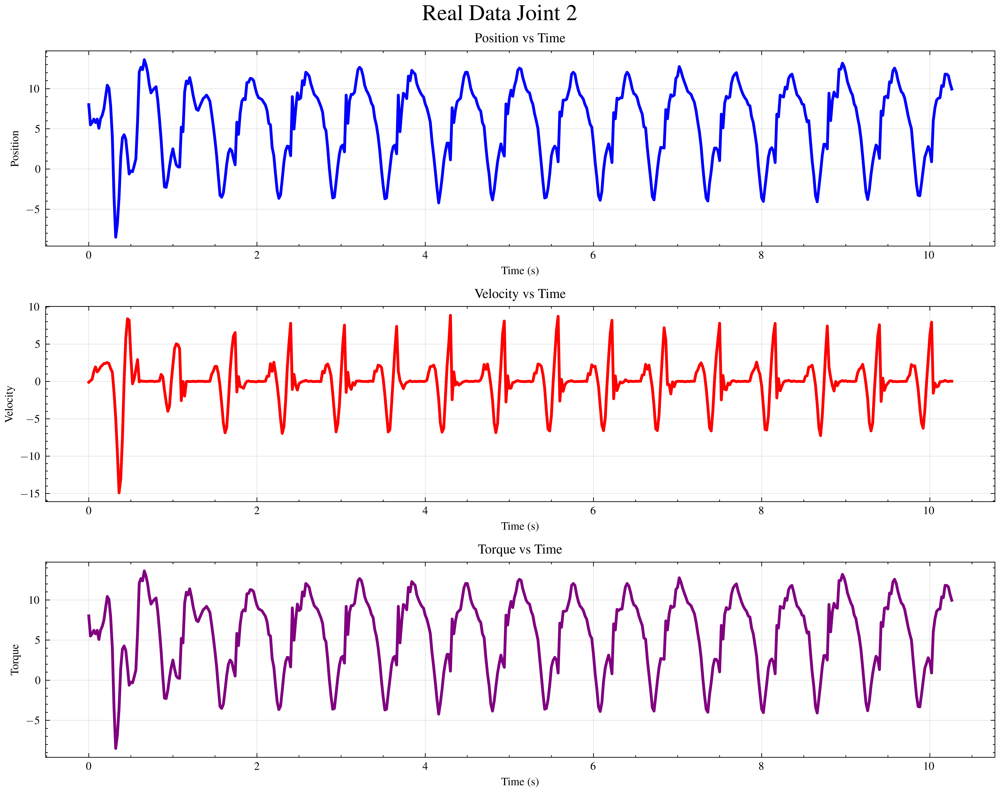

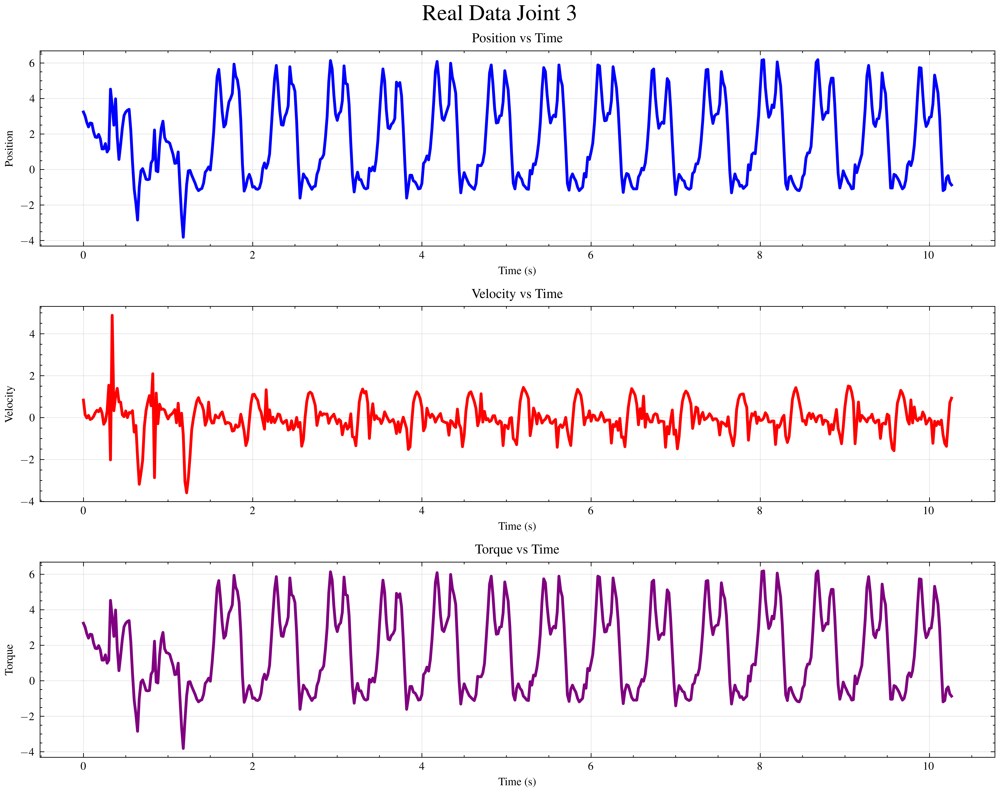

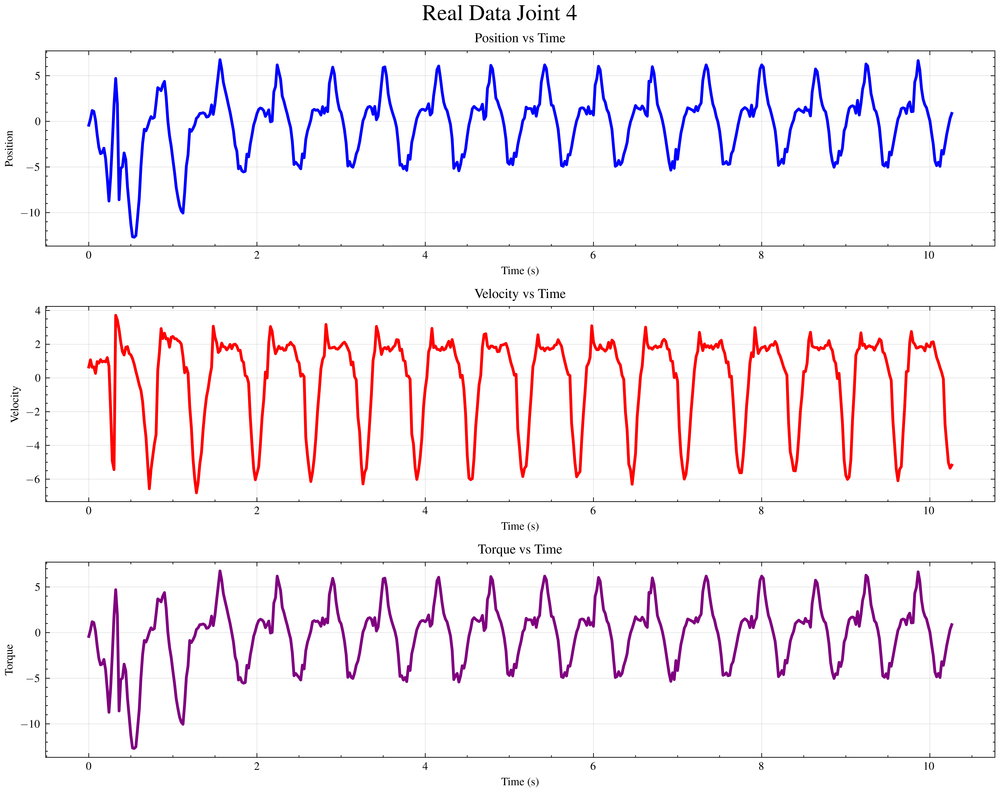

...

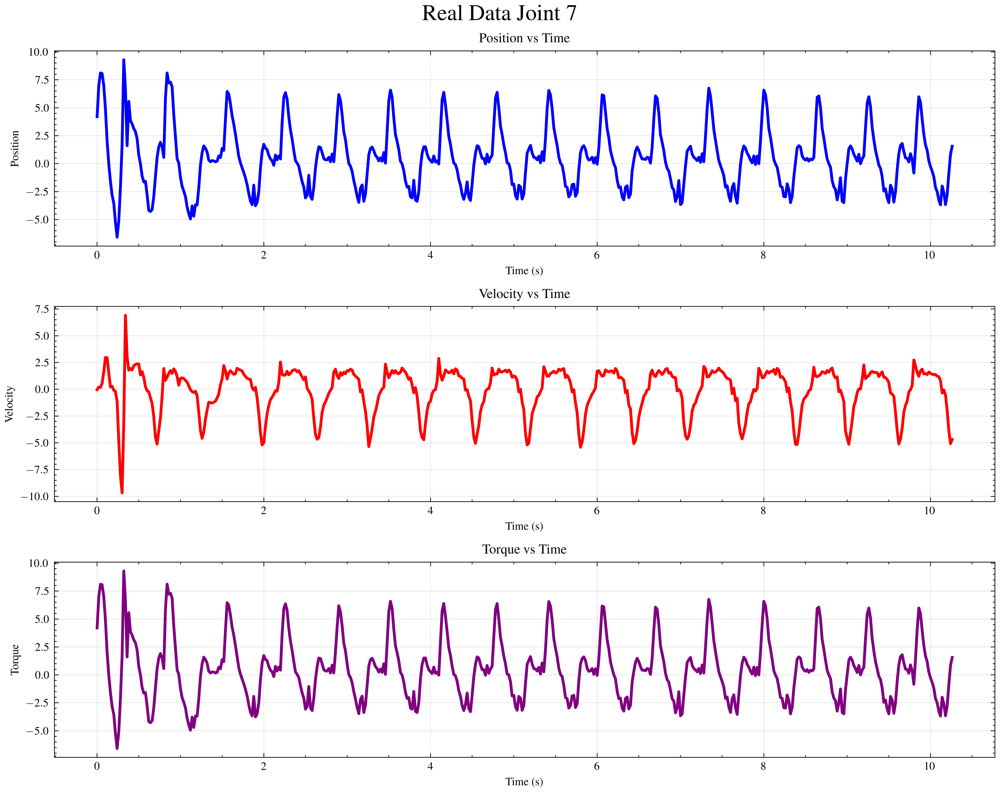

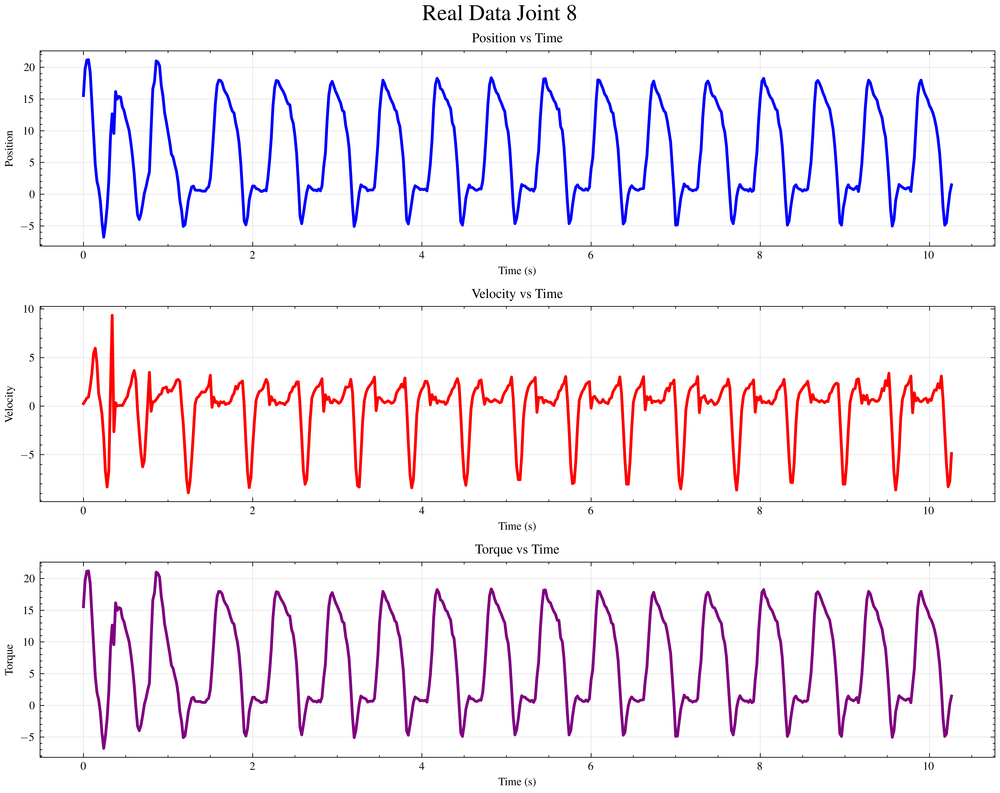

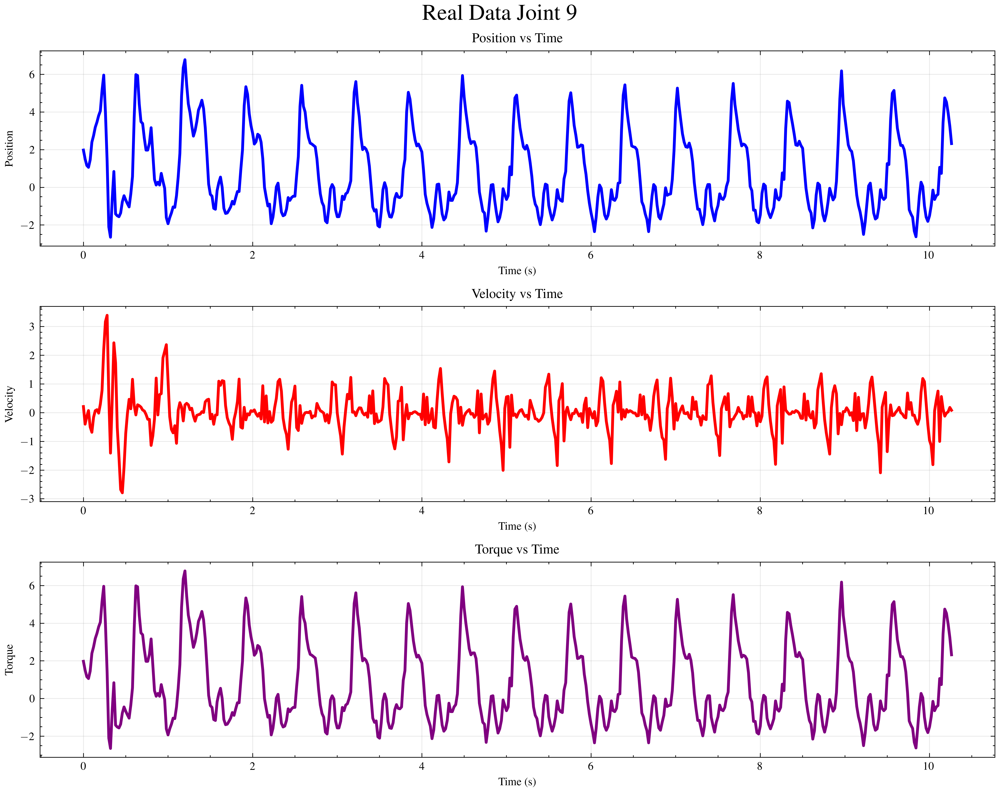

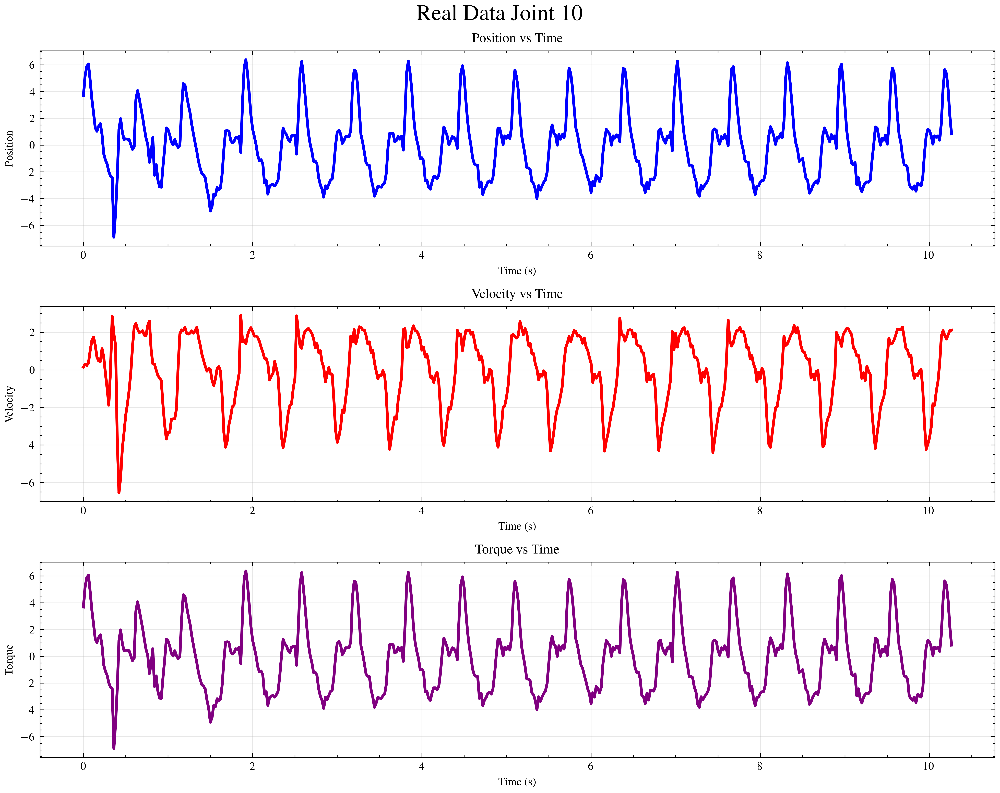

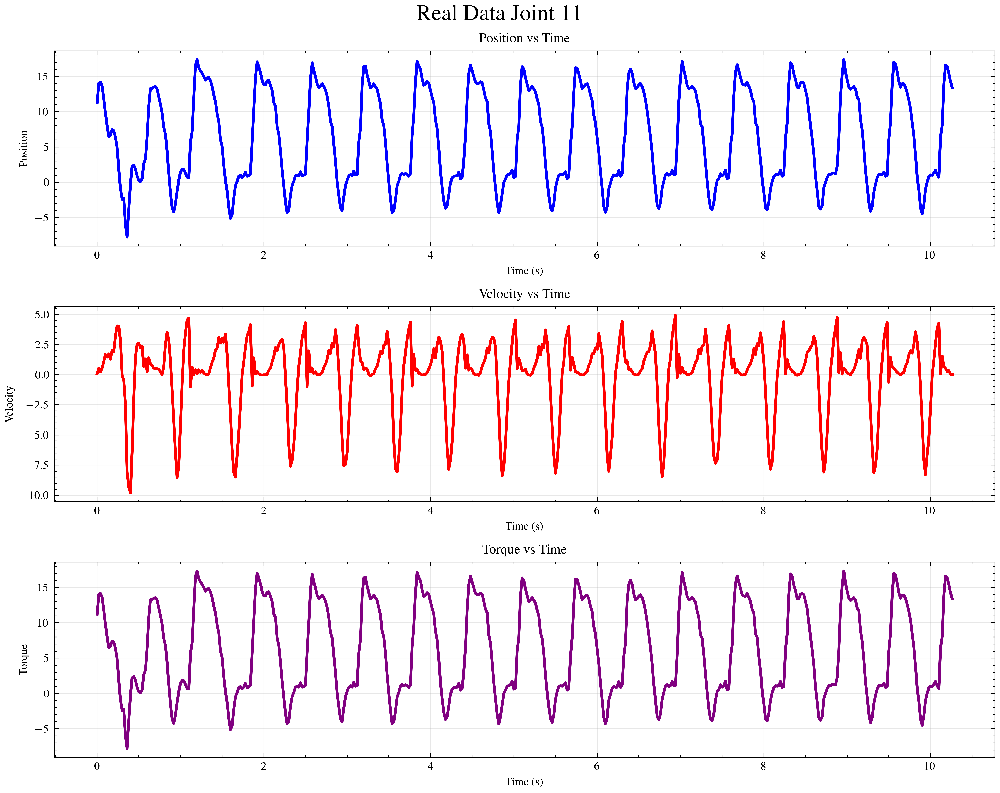

In [11]:
realDataPath = str((currentDir / "real_data").resolve())
realPos = np.load(realDataPath + "/pos_real.npy")
realVel = np.load(realDataPath + "/vel_real.npy")
realTau = np.load(realDataPath + "/tau_real.npy")
time = np.arange(0, 514 * 0.02, 0.02)

with plt.style.context(['science','ieee']):
  for i in range(12):
    fig, axes = plt.subplots(3, 1, figsize=(10, 8))
    fig.suptitle(f'Real Data Joint {i} ', fontsize=16, fontweight='bold')

    axes[0].plot(time, realPos[:, i], 'b-', linewidth=2)
    axes[0].set_title('Position vs Time')
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Position')
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(time, realVel[:, i], 'r-', linewidth=2)
    axes[1].set_title('Velocity vs Time')
    axes[1].set_xlabel('Time (s)')
    axes[1].set_ylabel('Velocity')
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(time, realTau[:, i], 'purple', linewidth=2)
    axes[2].set_title('Torque vs Time')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('Torque')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(plot_dir / f'real_data_joint_{i}.png', dpi=300, bbox_inches='tight')
    plt.show()

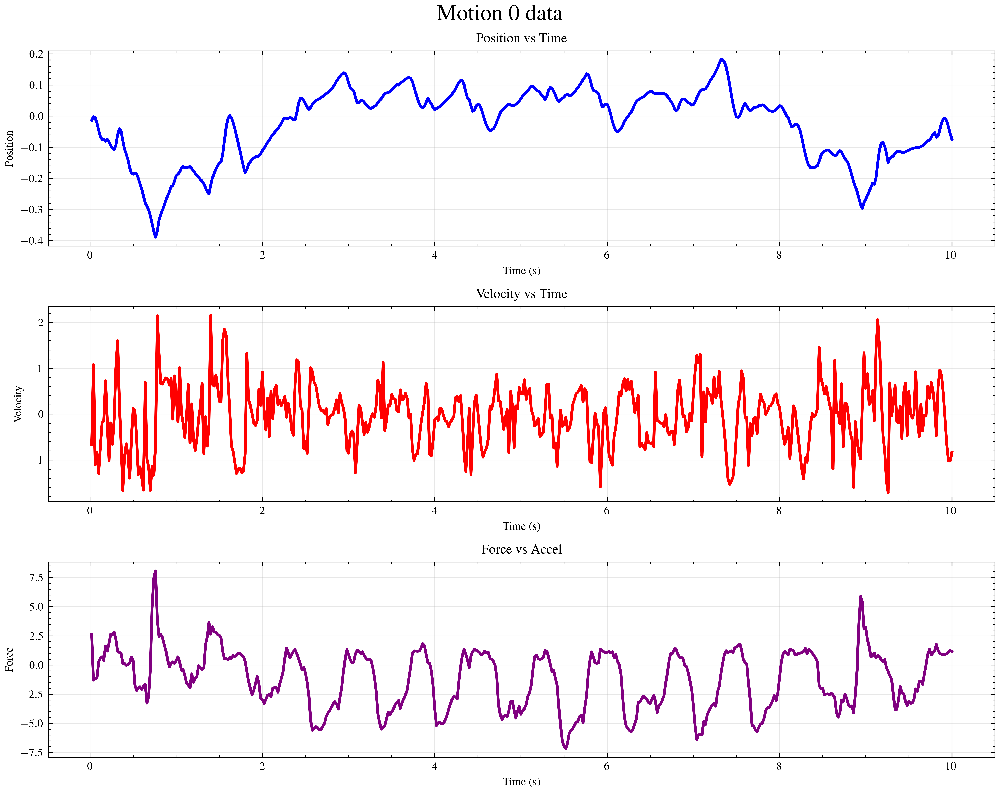

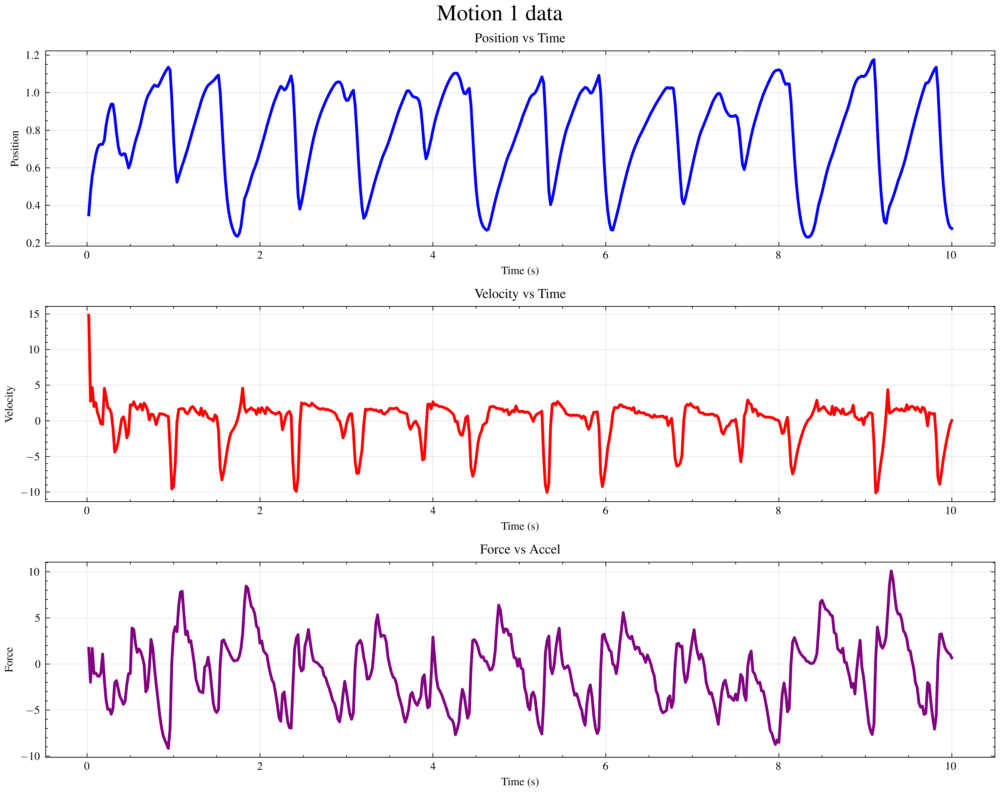

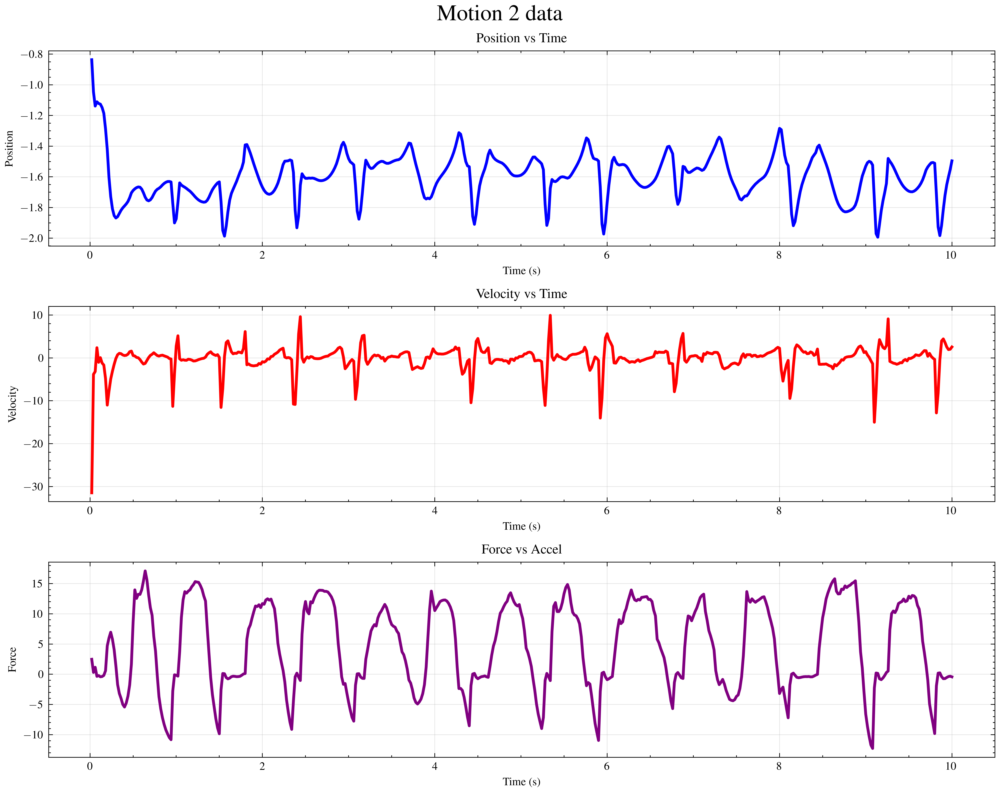

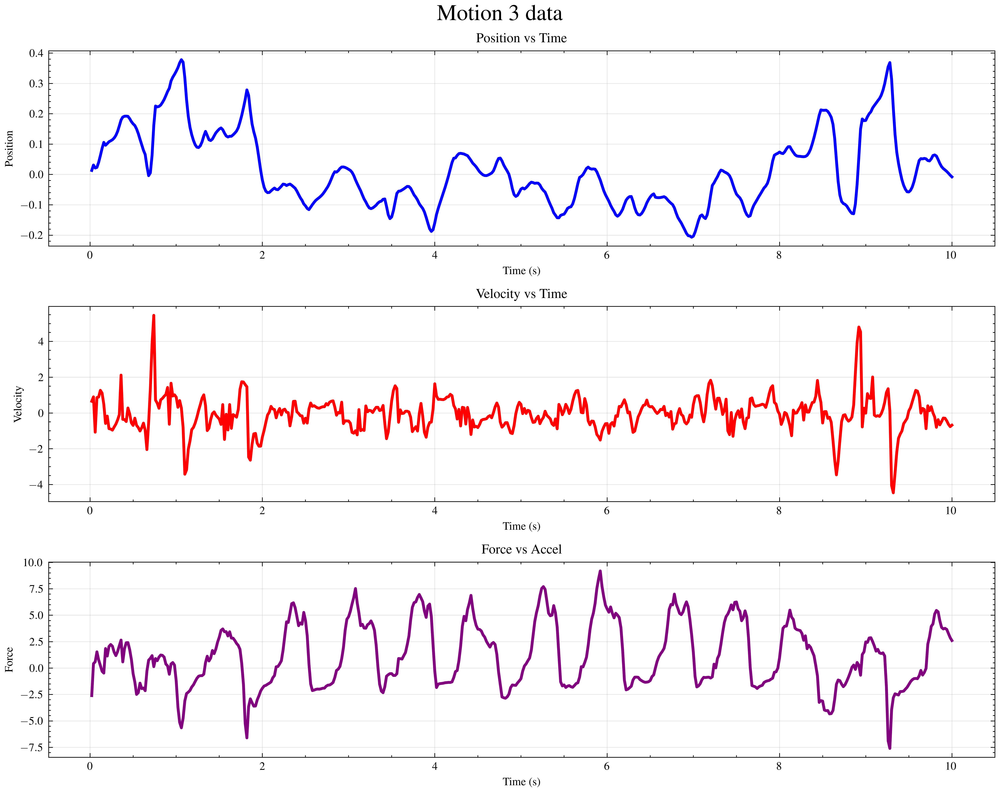

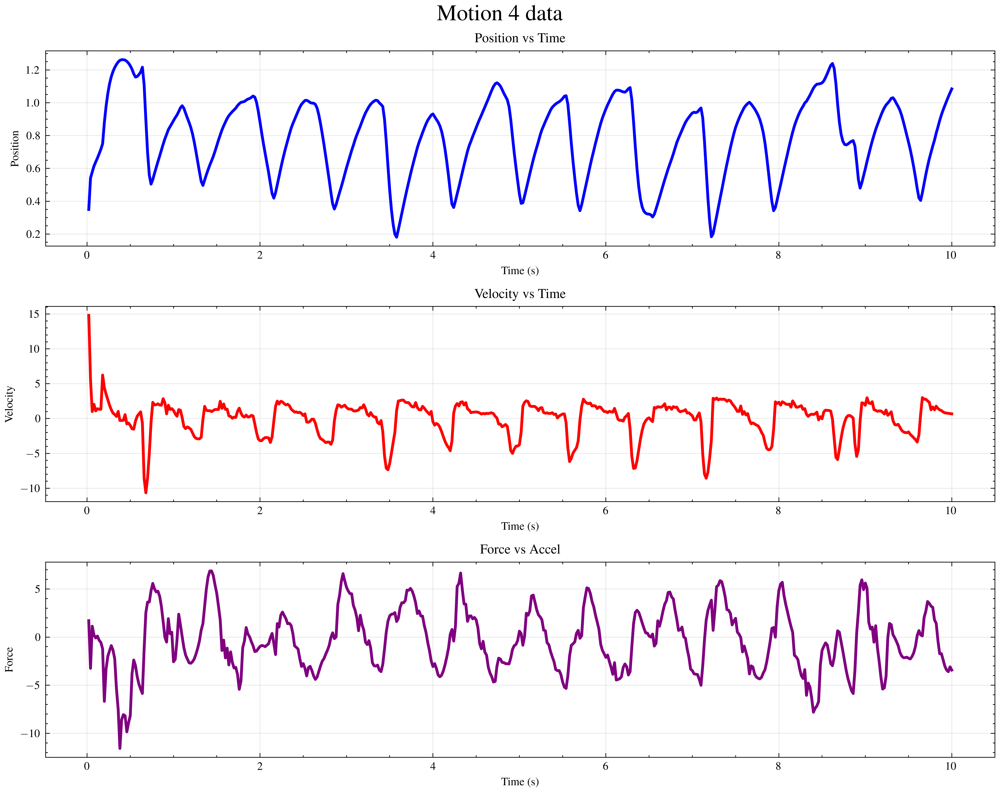

...

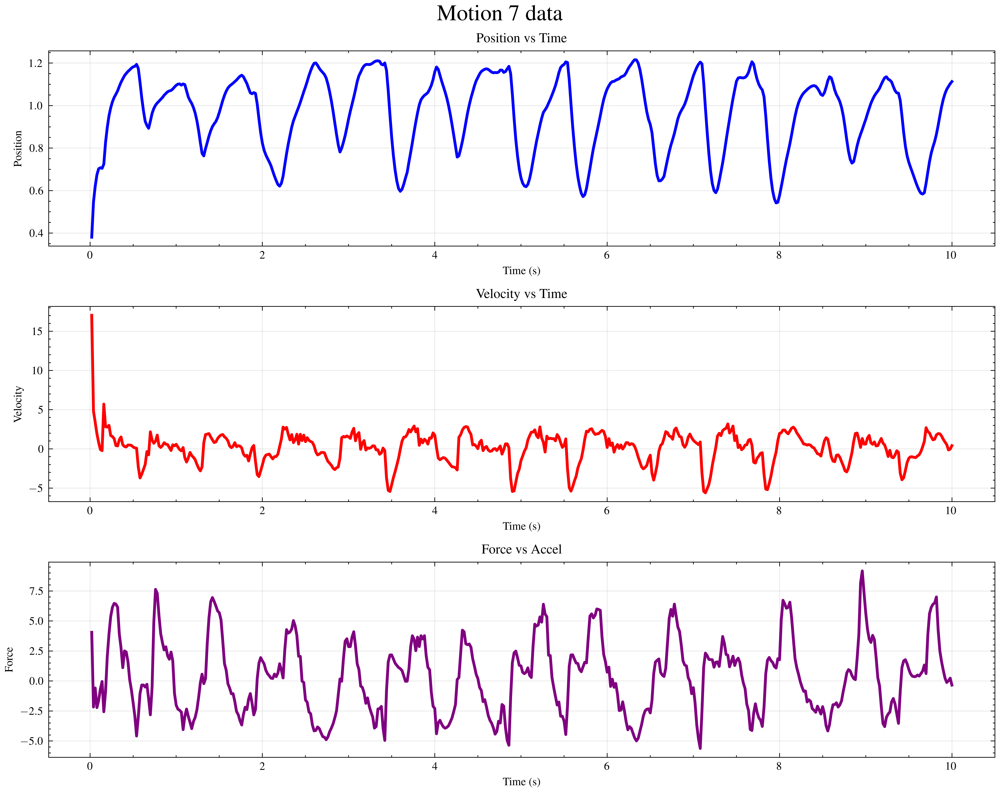

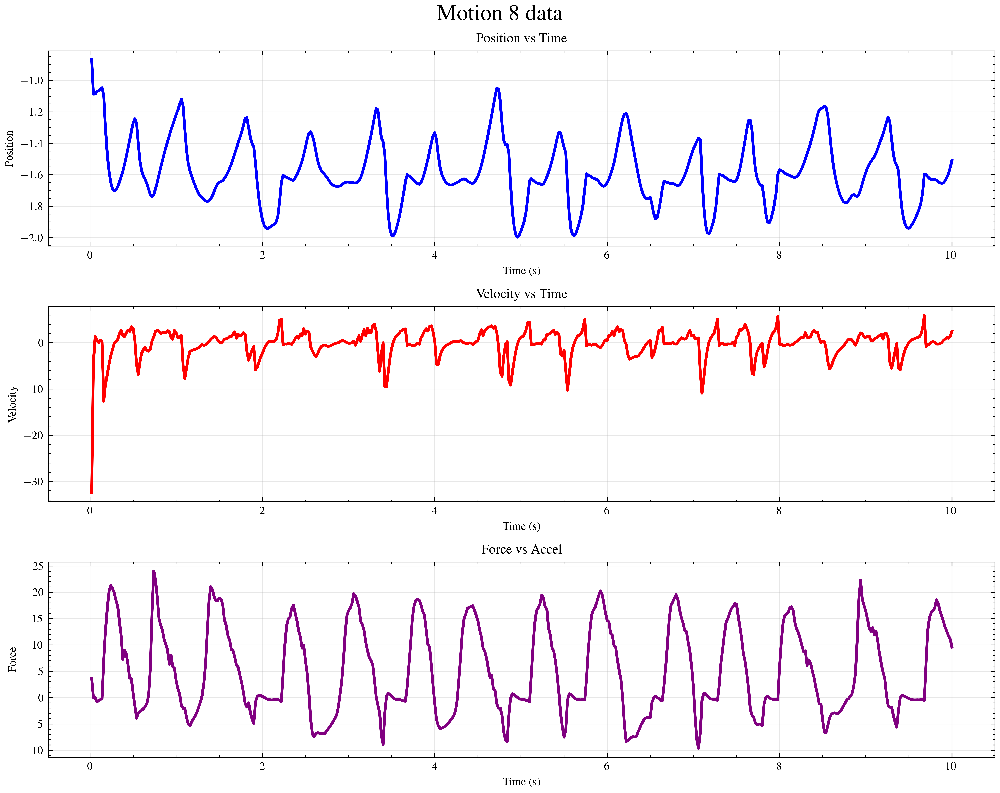

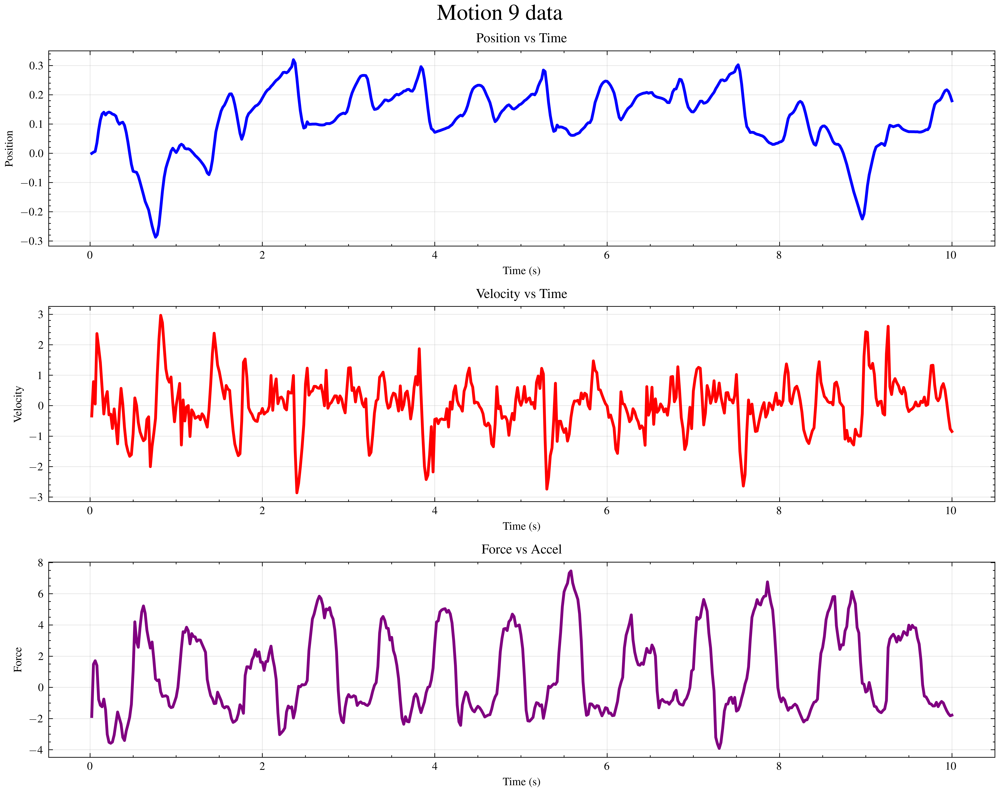

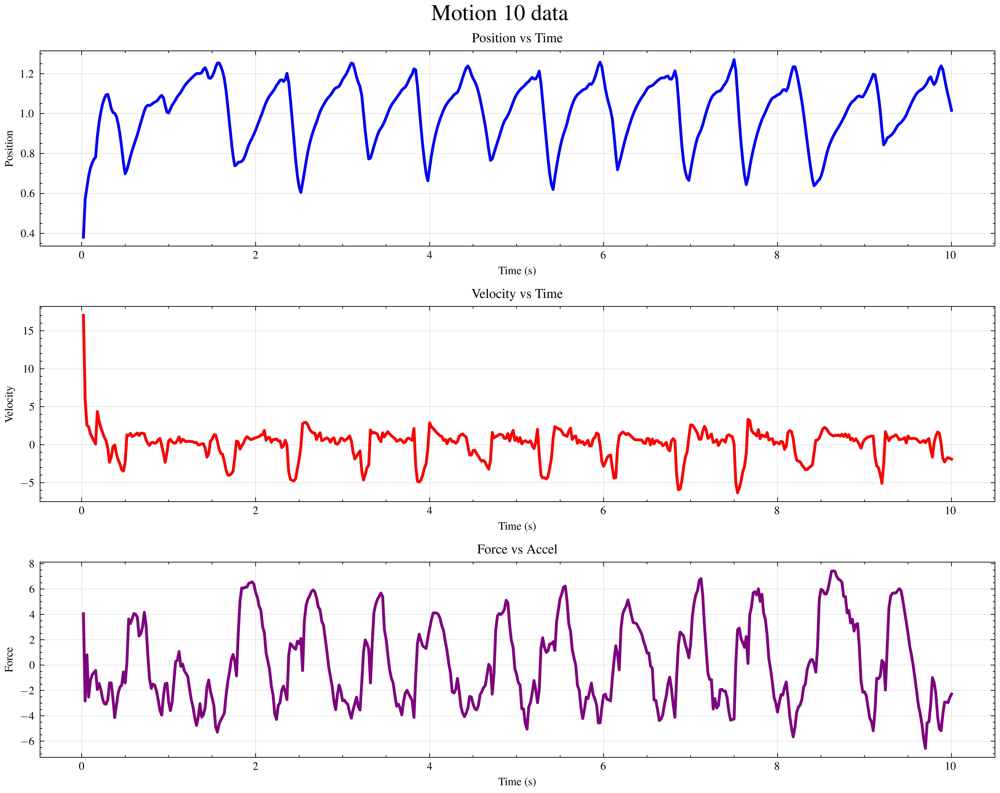

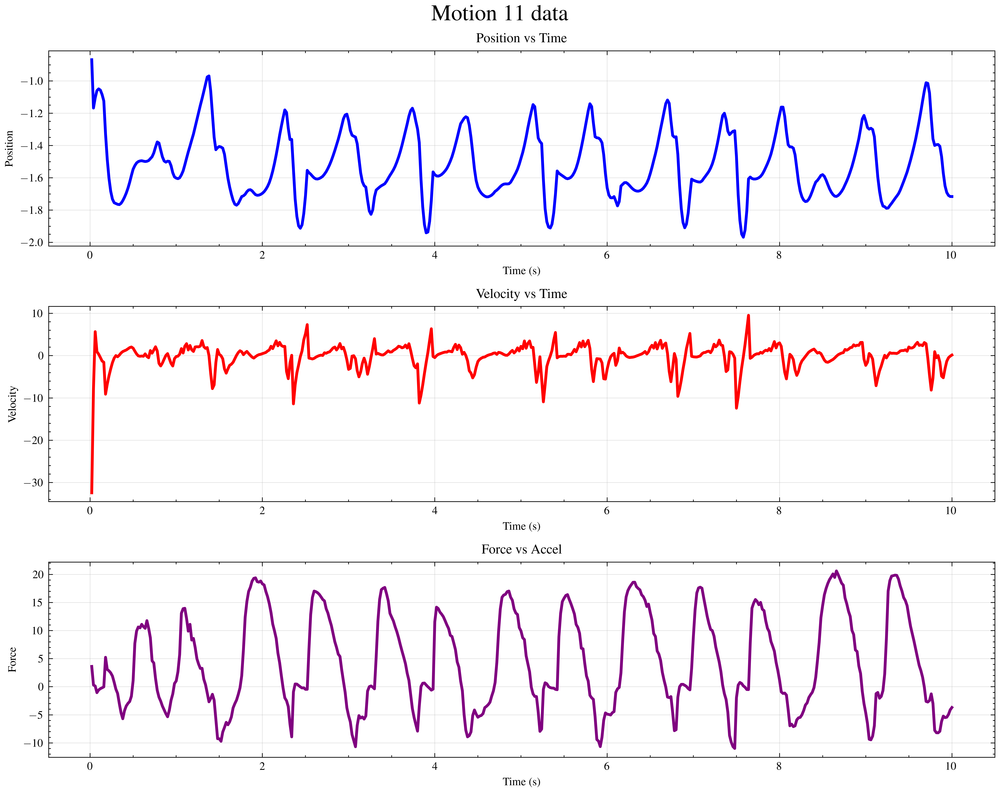

In [12]:
# gives the absolute path of .py and .ipynb where you are running your code. 
currentDir = pathlib.Path(os.path.abspath(""))
dataPath = str((currentDir / "motion_data").resolve())
plot_dir = currentDir / "motion_plots"

# 窗口平均函数
def moving_average(data, window_size):
    """对数据进行移动平均滤波"""
    window = np.ones(int(window_size)) / float(window_size)
    return np.convolve(data, window, 'same')

# 通过速度差分计算加速度的函数
def calculate_acceleration_from_velocity(time, velocity):
    """
    通过速度差分计算加速度
    加速度[i] = (速度[i] - 速度[i-1]) / (时间[i] - 时间[i-1])
    第一个点的加速度设为0
    """
    acceleration = np.zeros_like(velocity)
    for i in range(1, len(velocity)):
        dt = time[i] - time[i-1]
        if dt > 0:  # 避免除以零
            acceleration[i] = (velocity[i] - velocity[i-1]) / dt
    return acceleration

with plt.style.context(['science','ieee']):
  for i in range(12):
    motionData = np.genfromtxt(dataPath + f"/motion_{i}.csv", delimiter=",").transpose()
    # 假设数据列的顺序为：时间、位置、速度、加速度、力
    # 如果顺序不同，请根据实际数据调整索引
    time = motionData[0]        # 时间
    position = motionData[1]    # 位置
    velocity = motionData[2]    # 速度
    # # 计算时间步长
    # dt = time[1] - time[0] if len(time) > 1 else 0.001
    
    # acceleration_smoothed = calculate_acceleration_from_velocity(time, velocity)
    # acceleration = motionData[3] # 加速度
    force = motionData[4]       # 力

    # 创建2x2的子图布局
    fig, axes = plt.subplots(3, 1, figsize=(10, 8))
    fig.suptitle(f'Motion {i} data', fontsize=16, fontweight='bold')

    # 位置-时间图
    axes[0].plot(time, position, 'b-', linewidth=2)
    axes[0].set_title('Position vs Time')
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Position')
    axes[0].grid(True, alpha=0.3)

    # 速度-时间图
    axes[1].plot(time, velocity, 'r-', linewidth=2)
    axes[1].set_title('Velocity vs Time')
    axes[1].set_xlabel('Time (s)')
    axes[1].set_ylabel('Velocity')
    axes[1].grid(True, alpha=0.3)
    
    # # 加速度-时间图
    # axes[1, 0].plot(time, acceleration_smoothed, 'g-', linewidth=2)
    # axes[1, 0].plot(time, acceleration, 'r-', linewidth=1)
    # # axes[1, 0].plot(time, acceleration, 'g-', linewidth=2)
    # axes[1, 0].set_title('Accel vs Time')
    # axes[1, 0].set_xlabel('Time (s)')
    # axes[1, 0].set_ylabel('Accel')
    # axes[1, 0].grid(True, alpha=0.3)

    # 力-时间图
    axes[2].plot(time, force, 'purple', linewidth=2)
    axes[2].set_title('Force vs Accel')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('Force')
    axes[2].grid(True, alpha=0.3)

    # 调整布局
    plt.tight_layout()
    plt.savefig(plot_dir / f'motion_plot_{i}.png', dpi=300, bbox_inches='tight')
    plt.show()

  